# Clusterização de Regimes Climáticos de Recife (PE) com DBSCAN

Este notebook aplica **DBSCAN** à mesma base do `kmeans_recife.ipynb` (`../dados/df_recife_datetime.csv`, estação INMET A301, 2018–2021), reaproveitando as decisões de pré-processamento do K-Means para manter os resultados comparáveis. O foco é um só: **escolher e avaliar `eps` e `min_samples`**.

Roteiro enxuto:
1. **Dados e matriz de entrada** — mesmas 8 features do K-Means, `StandardScaler` e PCA de 6 componentes (configuração final do K-Means).
2. **Escolha analítica dos parâmetros** — regra para `min_samples`, curva de k-distância com detecção de joelho e varredura de sensibilidade para `eps`.
3. **Seis combinações**, cada uma em uma célula, com resultado simplificado (nº de clusters, % de ruído e silhouette).
4. **Tabela final** e seleção das melhores: **3 a 5 clusters** com uma quantidade palpável de ruído.

Chuva e identificadores ficam fora da matriz de entrada, como no K-Means.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
CAMINHO_CSV = "../dados/df_recife_datetime.csv"   # mesma base do kmeans_recife
PASTA_SAIDA = "../reports/dbscan_recife"
N_COMPONENTES_PCA = 6     # configuração final do K-Means (97,61% da variância)
TAM_AMOSTRA_SIL = 4000    # amostra fixa para a silhouette, como no K-Means

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 140)

---
## 1. Dados e matriz de entrada

Preparo idêntico ao do `kmeans_recife`: ordenação por `datetime`, conversão numérica, preenchimento causal (`ffill`) das quatro medições físicas e codificação cíclica de hora local (UTC-3) e mês. A chuva é mantida só como coluna auxiliar e **não entra** nas features.

In [2]:
VARIAVEL_CHUVA = "PRECIPITAÇÃO TOTAL, HORÁRIO (mm)"
VARIAVEIS_FISICAS = [
    "PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)",
    "TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)",
    "TEMPERATURA DO PONTO DE ORVALHO (°C)",
    "UMIDADE RELATIVA DO AR, HORARIA (%)",
]
VARIAVEIS_CICLICAS = ["hora_sin", "hora_cos", "mes_sin", "mes_cos"]
FEATURES_CLUSTER = VARIAVEIS_FISICAS + VARIAVEIS_CICLICAS
assert VARIAVEL_CHUVA not in FEATURES_CLUSTER


def converter_serie_numerica(serie: pd.Series) -> pd.Series:
    texto = serie.astype("string").str.strip().replace({
        "": pd.NA, "-": pd.NA, "--": pd.NA, "NaN": pd.NA, "nan": pd.NA,
        "null": pd.NA, "None": pd.NA, "-9999": pd.NA, "-9999,0": pd.NA, "-9999.0": pd.NA,
    })
    tem_virgula = texto.str.contains(",", na=False)
    texto = texto.mask(
        tem_virgula,
        texto.str.replace(".", "", regex=False).str.replace(",", ".", regex=False),
    )
    return pd.to_numeric(texto, errors="coerce").astype(float)


def preparar_dados_recife(caminho_csv: str = CAMINHO_CSV) -> pd.DataFrame:
    df = pd.read_csv(caminho_csv, dtype=str)
    df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce", utc=True)
    df = df.dropna(subset=["datetime"]).sort_values("datetime").drop_duplicates("datetime").reset_index(drop=True)

    for col in VARIAVEIS_FISICAS + [VARIAVEL_CHUVA]:
        df[col] = converter_serie_numerica(df[col])
    for col in VARIAVEIS_FISICAS:
        df[col] = df[col].ffill()          # preenchimento causal
    df = df.dropna(subset=VARIAVEIS_FISICAS)
    df["chuva_mm"] = df[VARIAVEL_CHUVA].fillna(0.0)   # apenas validação externa

    local = df["datetime"].dt.tz_convert("America/Recife")
    df["hora_local"] = local.dt.hour
    df["mes"] = local.dt.month
    df["hora_sin"] = np.sin(2 * np.pi * df["hora_local"] / 24.0)
    df["hora_cos"] = np.cos(2 * np.pi * df["hora_local"] / 24.0)
    df["mes_sin"] = np.sin(2 * np.pi * df["mes"] / 12.0)
    df["mes_cos"] = np.cos(2 * np.pi * df["mes"] / 12.0)
    return df


df_tratado = preparar_dados_recife()
print(f"Registros: {len(df_tratado)} | período UTC: {df_tratado['datetime'].min():%Y-%m-%d} a {df_tratado['datetime'].max():%Y-%m-%d}")
print(f"Features ({len(FEATURES_CLUSTER)}): {FEATURES_CLUSTER}")
print(f"Valores ausentes nas features: {int(df_tratado[FEATURES_CLUSTER].isna().sum().sum())}")

Registros: 33371 | período UTC: 2018-01-03 a 2021-11-12
Features (8): ['PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)', 'TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)', 'TEMPERATURA DO PONTO DE ORVALHO (°C)', 'UMIDADE RELATIVA DO AR, HORARIA (%)', 'hora_sin', 'hora_cos', 'mes_sin', 'mes_cos']
Valores ausentes nas features: 0


In [3]:
# StandardScaler + PCA(6), como no K-Means final. Não é preciso refazer a comparação de normalização/PCA.
X_std = StandardScaler().fit_transform(df_tratado[FEATURES_CLUSTER])
pca = PCA(n_components=N_COMPONENTES_PCA, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_std)
D = X_pca.shape[1]   # dimensão do espaço em que o DBSCAN será executado

# Amostra fixa e reprodutível para a silhouette (igual à usada no K-Means)
amostra_idx = np.random.default_rng(RANDOM_STATE).choice(len(X_pca), size=min(TAM_AMOSTRA_SIL, len(X_pca)), replace=False)

print(f"Espaço do DBSCAN: {X_pca.shape[0]} pontos x {D} dimensões "
      f"({pca.explained_variance_ratio_.sum() * 100:.2f}% da variância retida)")

Espaço do DBSCAN: 33371 pontos x 6 dimensões (97.61% da variância retida)


---
## 2. Escolha analítica de `min_samples` e `eps`

**`min_samples`.** A regra clássica é `min_samples ≥ D + 1` e, na prática, `2·D`; para bases grandes ou com ruído usa-se um múltiplo maior. Com `D = 6`, testamos **2·D = 12**, **3·D = 18** e **4·D = 24**.

**`eps`.** Para cada `min_samples`, calculamos a distância de cada ponto ao seu `min_samples`-ésimo vizinho (o próprio ponto conta como o 1º, como no DBSCAN do scikit-learn), ordenamos e procuramos o **joelho** da curva pelo método da corda (ponto mais distante da reta que une os extremos). O joelho separa pontos em região densa de pontos isolados e dá a ordem de grandeza de `eps`.

,regra,min_samples,eps_joelho,posicao_na_curva_pct,clusters_no_joelho,ruido_no_joelho_pct
0,2·D,12,0.760,93.1,2,1.44
1,3·D,18,0.849,94.2,1,0.91
2,4·D,24,0.875,92.8,1,1.00


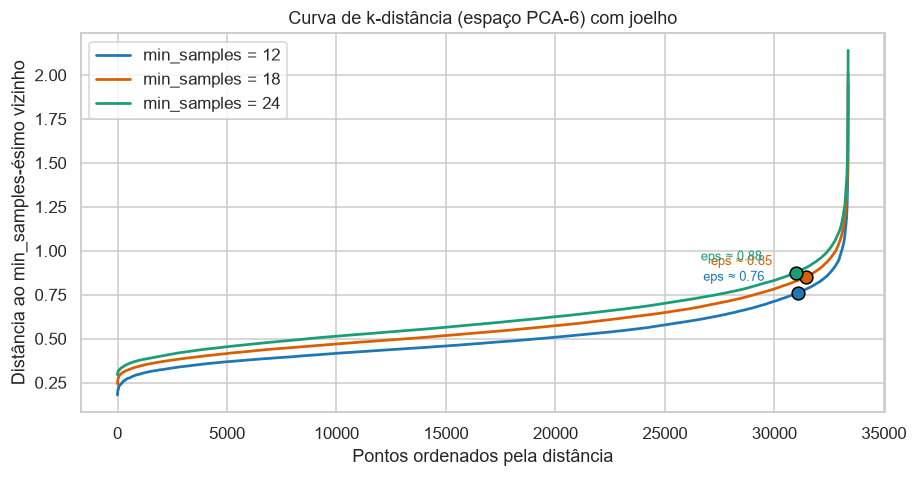

In [4]:
def joelho(curva_ordenada: np.ndarray) -> int:
    """Índice do joelho: ponto da curva normalizada mais distante da corda entre os extremos."""
    n = len(curva_ordenada)
    x = np.arange(n) / (n - 1)
    y = (curva_ordenada - curva_ordenada[0]) / (curva_ordenada[-1] - curva_ordenada[0])
    return int(np.argmax(x - y))


def ajustar_dbscan(min_samples: int, eps: float) -> np.ndarray:
    return DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_pca)


MIN_SAMPLES_CANDIDATOS = {"2·D": 2 * D, "3·D": 3 * D, "4·D": 4 * D}

dist_vizinhos, _ = NearestNeighbors(n_neighbors=max(MIN_SAMPLES_CANDIDATOS.values())).fit(X_pca).kneighbors(X_pca)

curvas, linhas = {}, []
for regra, ms in MIN_SAMPLES_CANDIDATOS.items():
    kd = np.sort(dist_vizinhos[:, ms - 1])
    i = joelho(kd)
    curvas[ms] = (kd, i)
    rot = ajustar_dbscan(ms, float(kd[i]))
    linhas.append({
        "regra": regra,
        "min_samples": ms,
        "eps_joelho": round(float(kd[i]), 3),
        "posicao_na_curva_pct": round(100 * i / len(kd), 1),
        "clusters_no_joelho": len(set(rot) - {-1}),
        "ruido_no_joelho_pct": round(float((rot == -1).mean() * 100), 2),
    })
tabela_joelho = pd.DataFrame(linhas)
display(tabela_joelho)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
for (ms, (kd, i)), cor in zip(curvas.items(), ["#1f77b4", "#d95f02", "#1b9e77"]):
    ax.plot(np.arange(len(kd)), kd, color=cor, linewidth=1.8, label=f"min_samples = {ms}")
    ax.scatter(i, kd[i], color=cor, edgecolors="black", s=70, zorder=5)
    ax.annotate(f"eps ≈ {kd[i]:.2f}", (i, kd[i]), textcoords="offset points", xytext=(-62, 8), fontsize=8.5, color=cor)
ax.set_title("Curva de k-distância (espaço PCA-6) com joelho")
ax.set_xlabel("Pontos ordenados pela distância")
ax.set_ylabel("Distância ao min_samples-ésimo vizinho")
ax.legend()
plt.tight_layout()
plt.show()

O joelho cai em ~93% da curva para os três `min_samples`, mas **nesta base ele funde tudo em 1 ou 2 clusters** (coluna `clusters_no_joelho`): os regimes climáticos formam um contínuo (ciclos de hora e mês), ligado por pontos "ponte". O joelho serve então como **limite superior** de `eps`; os clusters aparecem abaixo dele.

Para localizar a faixa útil sem chute, fazemos uma **varredura de sensibilidade**: nº de clusters e % de ruído para cada par (`min_samples`, `eps`) numa grade abaixo e em torno do joelho. A janela escolhida é formada pelos valores de `eps` em que a **mediana** do nº de clusters entre os três `min_samples` fica entre 3 e 5; seus extremos viram os dois valores de `eps` a testar.

In [5]:
GRADE_EPS = np.round(np.arange(0.56, 0.761, 0.02), 2)

registros = []
for ms in MIN_SAMPLES_CANDIDATOS.values():
    for eps in GRADE_EPS:
        rot = ajustar_dbscan(ms, float(eps))
        registros.append({
            "min_samples": ms,
            "eps": float(eps),
            "clusters": len(set(rot) - {-1}),
            "ruido_pct": round(float((rot == -1).mean() * 100), 1),
        })
varredura = pd.DataFrame(registros)

print("Nº de clusters por eps (linhas) e min_samples (colunas):")
tab_clusters = varredura.pivot(index="eps", columns="min_samples", values="clusters")
display(tab_clusters)

print("\n% de ruído por eps (linhas) e min_samples (colunas):")
display(varredura.pivot(index="eps", columns="min_samples", values="ruido_pct"))

mediana_clusters = tab_clusters.median(axis=1)
janela = mediana_clusters[(mediana_clusters >= 3) & (mediana_clusters <= 5)].index
assert len(janela) > 0, "Nenhum eps da grade produziu mediana de 3 a 5 clusters."
EPS_BAIXO, EPS_ALTO = float(janela.min()), float(janela.max())

MS_2D, MS_3D, MS_4D = MIN_SAMPLES_CANDIDATOS.values()
print(f"\nJanela de eps com mediana de 3 a 5 clusters: {EPS_BAIXO:.2f} a {EPS_ALTO:.2f}")
print(f"Seis combinações = min_samples {{{MS_2D}, {MS_3D}, {MS_4D}}} x eps {{{EPS_BAIXO:.2f}, {EPS_ALTO:.2f}}}")

Nº de clusters por eps (linhas) e min_samples (colunas):


min_samples,12,18,24
eps,,,
0.56,7,8,10
0.58,10,8,7
0.60,7,7,6
0.62,4,6,5
0.64,5,4,4
0.66,5,4,4
0.68,3,2,2
0.70,2,2,2
0.72,2,2,2



% de ruído por eps (linhas) e min_samples (colunas):


min_samples,12,18,24
eps,,,
0.56,11.2,18.2,26.2
0.58,9.5,15.1,21.9
0.60,7.7,12.4,18.1
0.62,6.3,10.4,15.0
0.64,5.1,8.5,12.3
0.66,4.2,7.0,10.1
0.68,3.3,5.7,8.4
0.70,2.8,4.6,6.9
0.72,2.2,3.7,5.5



Janela de eps com mediana de 3 a 5 clusters: 0.62 a 0.66
Seis combinações = min_samples {12, 18, 24} x eps {0.62, 0.66}


---
## 3. Seis combinações

Cada célula roda uma combinação e guarda: **nº de clusters**, **% de ruído** e **silhouette**. Detalhes do cálculo:
- A **silhouette** usa a amostra fixa de 4.000 pontos, **sem os pontos de ruído**, e só existe quando há pelo menos 2 clusters (caso contrário fica `NaN`).
- O **menor cluster (%)** também é guardado, para identificar microclusters sem interpretação.

In [6]:
resultados = {}   # nome -> métricas
rotulos = {}      # nome -> rótulos por registro (-1 = ruído)


def rodar_dbscan(nome: str, min_samples: int, eps: float) -> dict:
    rot = ajustar_dbscan(min_samples, eps)
    n_clusters = len(set(rot) - {-1})
    ruido_pct = float((rot == -1).mean() * 100)
    tamanhos = np.sort(np.bincount(rot[rot != -1]))[::-1] if n_clusters else np.array([], dtype=int)
    menor_pct = float(tamanhos.min() / len(rot) * 100) if n_clusters else np.nan

    rot_amostra = rot[amostra_idx]
    sem_ruido = rot_amostra != -1
    if len(set(rot_amostra[sem_ruido])) >= 2:
        sil = float(silhouette_score(X_pca[amostra_idx][sem_ruido], rot_amostra[sem_ruido]))
    else:
        sil = np.nan

    resultados[nome] = {
        "combinacao": nome, "min_samples": min_samples, "eps": round(eps, 2),
        "clusters": n_clusters, "ruido_pct": round(ruido_pct, 2),
        "silhouette": round(sil, 4) if not np.isnan(sil) else np.nan,
        "menor_cluster_pct": round(menor_pct, 3) if not np.isnan(menor_pct) else np.nan,
    }
    rotulos[nome] = rot
    print(f"{nome} | min_samples={min_samples} eps={eps:.2f} -> clusters={n_clusters} | ruído={ruido_pct:.2f}% "
          f"| silhouette={sil:.4f} | menor cluster={menor_pct:.2f}%")
    print(f"     tamanhos dos clusters (horas): {tamanhos.tolist()}")
    return resultados[nome]

In [7]:
# C1 — min_samples = 2·D, eps baixo da janela
_ = rodar_dbscan("C1", MS_2D, EPS_BAIXO)

C1 | min_samples=12 eps=0.62 -> clusters=4 | ruído=6.28% | silhouette=0.0166 | menor cluster=7.43%
     tamanhos dos clusters (horas): [13638, 12457, 2701, 2479]


In [8]:
# C2 — min_samples = 2·D, eps alto da janela
_ = rodar_dbscan("C2", MS_2D, EPS_ALTO)

C2 | min_samples=12 eps=0.66 -> clusters=5 | ruído=4.17% | silhouette=-0.0214 | menor cluster=0.03%
     tamanhos dos clusters (horas): [13871, 12805, 2770, 2523, 11]


In [9]:
# C3 — min_samples = 3·D, eps baixo da janela
_ = rodar_dbscan("C3", MS_3D, EPS_BAIXO)

C3 | min_samples=18 eps=0.62 -> clusters=6 | ruído=10.38% | silhouette=-0.0017 | menor cluster=0.17%
     tamanhos dos clusters (horas): [13212, 9354, 2543, 2406, 2334, 57]


In [10]:
# C4 — min_samples = 3·D, eps alto da janela
_ = rodar_dbscan("C4", MS_3D, EPS_ALTO)

C4 | min_samples=18 eps=0.66 -> clusters=4 | ruído=7.03% | silhouette=0.0175 | menor cluster=7.40%
     tamanhos dos clusters (horas): [13610, 12311, 2635, 2470]


In [11]:
# C5 — min_samples = 4·D, eps baixo da janela
_ = rodar_dbscan("C5", MS_4D, EPS_BAIXO)

C5 | min_samples=24 eps=0.62 -> clusters=5 | ruído=14.99% | silhouette=0.0296 | menor cluster=6.07%
     tamanhos dos clusters (horas): [12757, 8924, 2376, 2286, 2027]


In [12]:
# C6 — min_samples = 4·D, eps alto da janela
_ = rodar_dbscan("C6", MS_4D, EPS_ALTO)

C6 | min_samples=24 eps=0.66 -> clusters=4 | ruído=10.06% | silhouette=0.0212 | menor cluster=7.20%
     tamanhos dos clusters (horas): [13299, 11780, 2534, 2402]


---
## 4. Tabela final e escolha das melhores

Critérios para uma combinação ser considerada boa:
- **3 a 5 clusters**;
- **ruído palpável**: entre 2% e 12% das horas (menos que isso é ruído simbólico; mais que isso descarta dados demais);
- **menor cluster com pelo menos 1%** das horas, para não contar microclusters de poucas dezenas de pontos como regime;
- entre as que atendem, o desempate é a **silhouette** (maior é melhor).

In [13]:
CRITERIOS = {"clusters_min": 3, "clusters_max": 5, "ruido_min": 2.0, "ruido_max": 12, "menor_cluster_min": 1.0}

df_resultados = pd.DataFrame(resultados.values())
df_resultados["atende"] = (
    df_resultados["clusters"].between(CRITERIOS["clusters_min"], CRITERIOS["clusters_max"])
    & df_resultados["ruido_pct"].between(CRITERIOS["ruido_min"], CRITERIOS["ruido_max"])
    & (df_resultados["menor_cluster_pct"] >= CRITERIOS["menor_cluster_min"])
)
df_resultados = df_resultados.sort_values(["atende", "silhouette"], ascending=[False, False]).reset_index(drop=True)

print("Resultado das 6 combinações (as que atendem aos critérios aparecem primeiro):")
display(df_resultados)

melhores = df_resultados[df_resultados["atende"]]
print(f"\nCombinações que atendem aos critérios: {len(melhores)} de {len(df_resultados)}")
for _, r in melhores.iterrows():
    print(f"  {r['combinacao']}: min_samples={int(r['min_samples'])}, eps={r['eps']:.2f} -> "
          f"{int(r['clusters'])} clusters, {r['ruido_pct']:.2f}% de ruído, silhouette {r['silhouette']:.4f}")

os.makedirs(PASTA_SAIDA, exist_ok=True)
df_resultados.to_csv(f"{PASTA_SAIDA}/metricas_dbscan.csv", index=False)
print(f"\nMétricas salvas em {PASTA_SAIDA}/metricas_dbscan.csv")

assert len(resultados) == 6 and df_resultados[["clusters", "ruido_pct"]].notna().all().all()
assert VARIAVEL_CHUVA not in FEATURES_CLUSTER

Resultado das 6 combinações (as que atendem aos critérios aparecem primeiro):


,combinacao,min_samples,eps,clusters,ruido_pct,silhouette,menor_cluster_pct,atende
0,C6,24,0.66,4,10.06,0.0212,7.198,True
1,C4,18,0.66,4,7.03,0.0175,7.402,True
2,C1,12,0.62,4,6.28,0.0166,7.429,True
3,C5,24,0.62,5,14.99,0.0296,6.074,False
4,C3,18,0.62,6,10.38,-0.0017,0.171,False
5,C2,12,0.66,5,4.17,-0.0214,0.033,False



Combinações que atendem aos critérios: 3 de 6
  C6: min_samples=24, eps=0.66 -> 4 clusters, 10.06% de ruído, silhouette 0.0212
  C4: min_samples=18, eps=0.66 -> 4 clusters, 7.03% de ruído, silhouette 0.0175
  C1: min_samples=12, eps=0.62 -> 4 clusters, 6.28% de ruído, silhouette 0.0166

Métricas salvas em ../reports/dbscan_recife/metricas_dbscan.csv


---
## 5. Visualização dos clusters

Cada gráfico mostra uma combinação em dois planos: a projeção **PC1 × PC2** (espaço onde o DBSCAN rodou) e **temperatura × umidade** (unidades físicas). Pontos cinza são ruído (`-1`).

**C1 · `min_samples = 12`, `eps = 0,62`** — 4 clusters, 6,28% de ruído, silhouette 0,0166. duas massas grandes (~13,6 e ~12,5 mil horas) e dois grupos pequenos (~2,7 e ~2,5 mil).

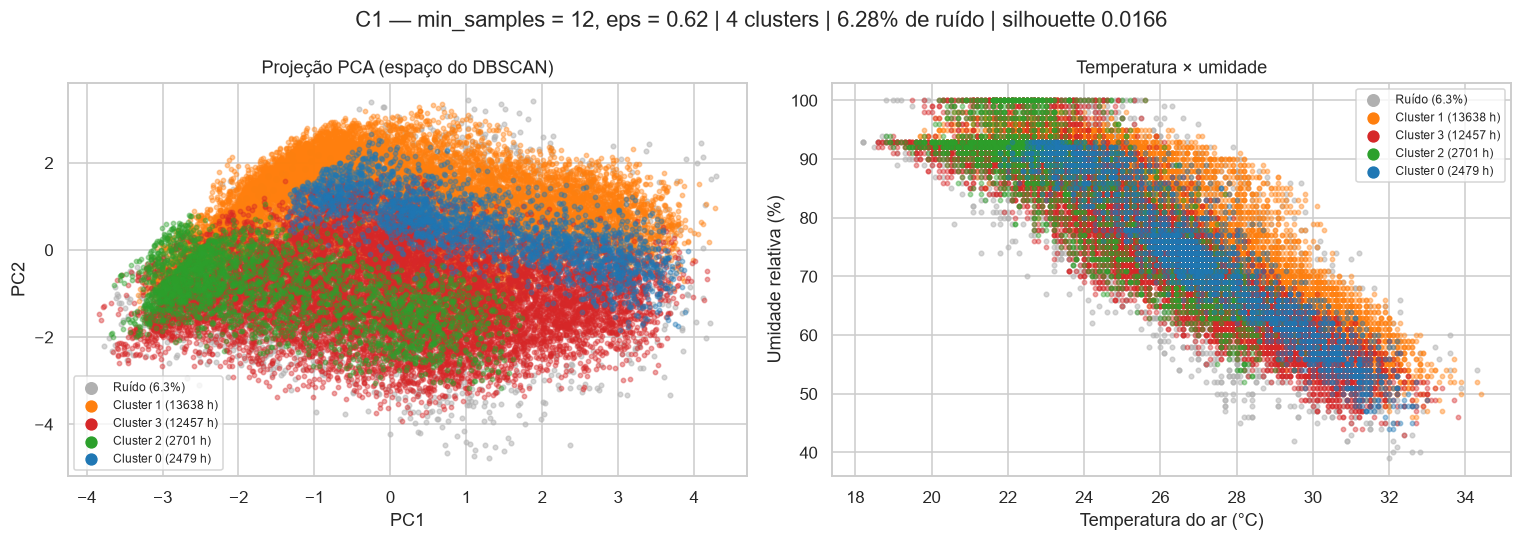

In [14]:
def plotar_clusters(nome: str) -> None:
    rot, r = rotulos[nome], resultados[nome]
    cor_temp, cor_umid = VARIAVEIS_FISICAS[1], VARIAVEIS_FISICAS[3]
    planos = [
        (X_pca[:, 0], X_pca[:, 1], "PC1", "PC2", "Projeção PCA (espaço do DBSCAN)"),
        (df_tratado[cor_temp].to_numpy(), df_tratado[cor_umid].to_numpy(),
         "Temperatura do ar (°C)", "Umidade relativa (%)", "Temperatura × umidade"),
    ]
    paleta = plt.get_cmap("tab10")
    ruido = rot == -1

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, (x, y, xl, yl, titulo) in zip(axes, planos):
        ax.scatter(x[ruido], y[ruido], c="#b0b0b0", s=9, alpha=0.5, label=f"Ruído ({r['ruido_pct']:.1f}%)")
        # do maior para o menor, para os clusters pequenos ficarem por cima
        for c in sorted(set(rot) - {-1}, key=lambda k: -int((rot == k).sum())):
            m = rot == c
            ax.scatter(x[m], y[m], color=paleta(c % 10), s=8, alpha=0.4, label=f"Cluster {c} ({int(m.sum())} h)")
        ax.set_title(titulo)
        ax.set_xlabel(xl)
        ax.set_ylabel(yl)
        leg = ax.legend(markerscale=2.5, fontsize=8, loc="best")
        for h in leg.legend_handles:
            h.set_alpha(1)

    sil = "n/d" if pd.isna(r["silhouette"]) else f"{r['silhouette']:.4f}"
    fig.suptitle(f"{nome} — min_samples = {r['min_samples']}, eps = {r['eps']:.2f} | "
                 f"{r['clusters']} clusters | {r['ruido_pct']:.2f}% de ruído | silhouette {sil}")
    plt.tight_layout()
    plt.show()


plotar_clusters("C1")

**C2 · `min_samples = 12`, `eps = 0,66`** — 5 clusters, 4,17% de ruído, silhouette -0,0214. **Reprovada:** o 5º cluster tem só 11 horas (microcluster), quase invisível no gráfico.

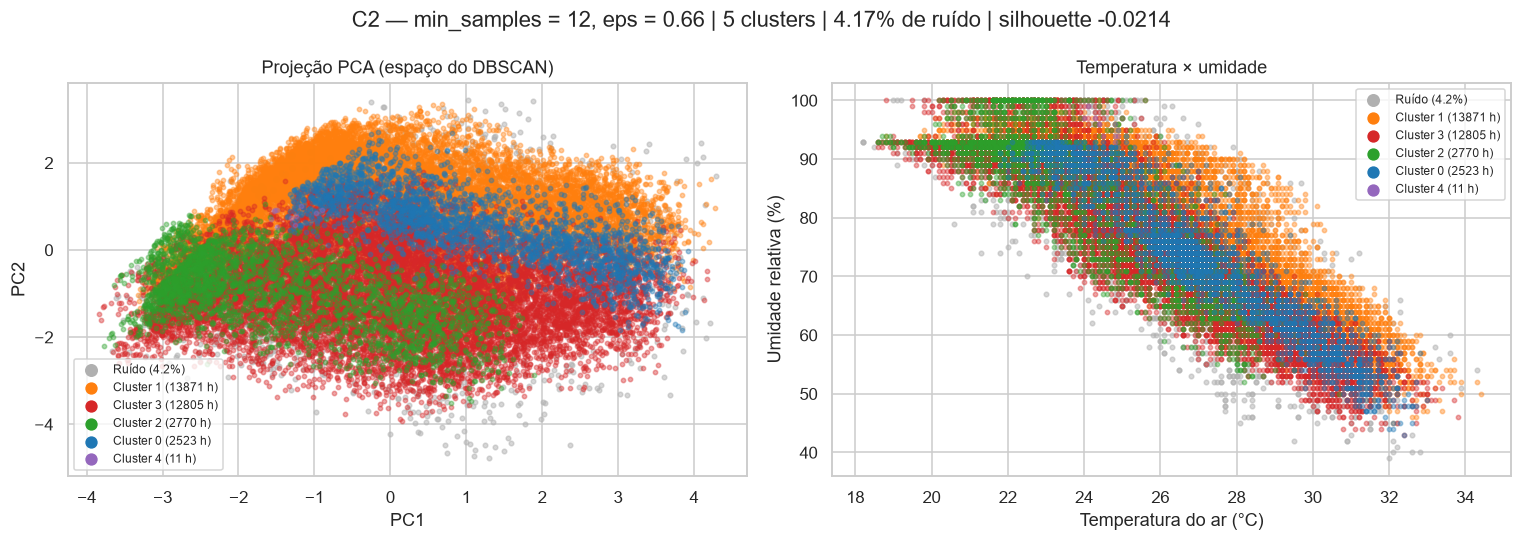

In [15]:
plotar_clusters("C2")

**C3 · `min_samples = 18`, `eps = 0,62`** — 6 clusters, 10,38% de ruído, silhouette -0,0017. fragmenta uma das massas grandes (13,2 e 9,4 mil horas) e tem um cluster de 57 horas.

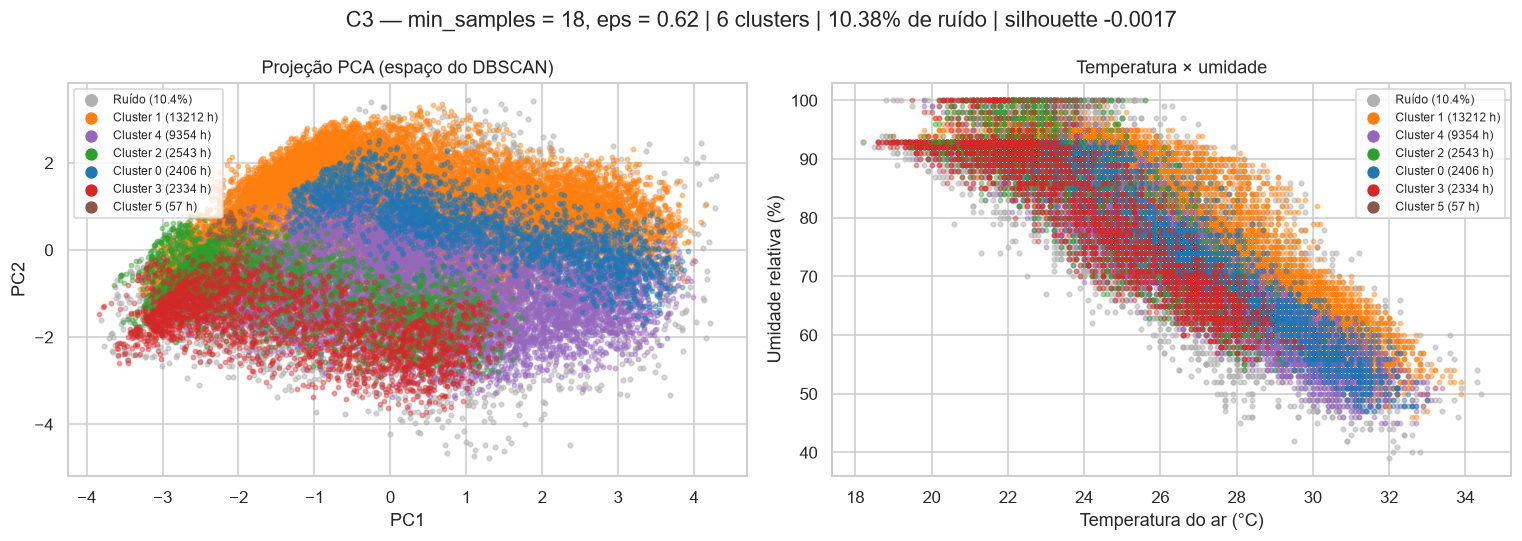

In [16]:
plotar_clusters("C3")

**C4 · `min_samples = 18`, `eps = 0,66`** — 4 clusters, 7,03% de ruído, silhouette 0,0175. **Aprovada:** mesma estrutura de C1 (13,6 e 12,3 mil horas, mais dois grupos de ~2,6 e ~2,5 mil), com um pouco mais de ruído.

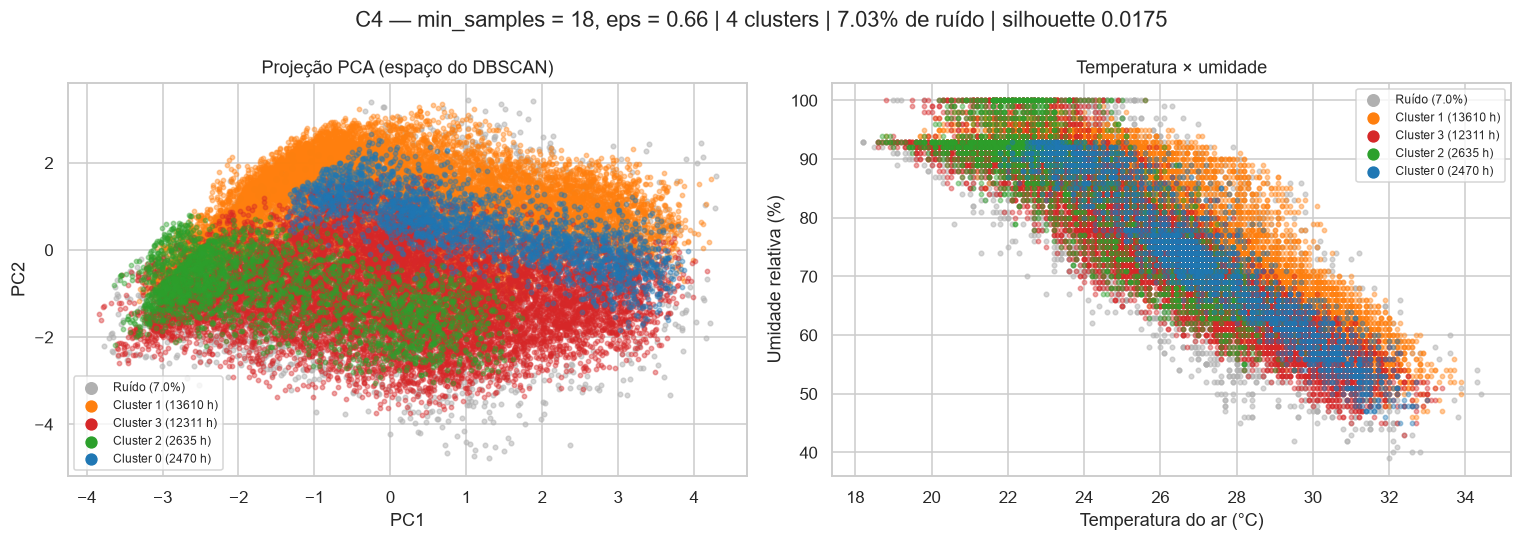

In [17]:
plotar_clusters("C4")

**C5 · `min_samples = 24`, `eps = 0,62`** — 5 clusters, 14,99% de ruído, silhouette 0,0296. **Reprovada só pelo ruído** (limite de 12%): a massa principal se divide em 12,8 e 8,9 mil horas e os três grupos menores têm de 2,0 a 2,4 mil.

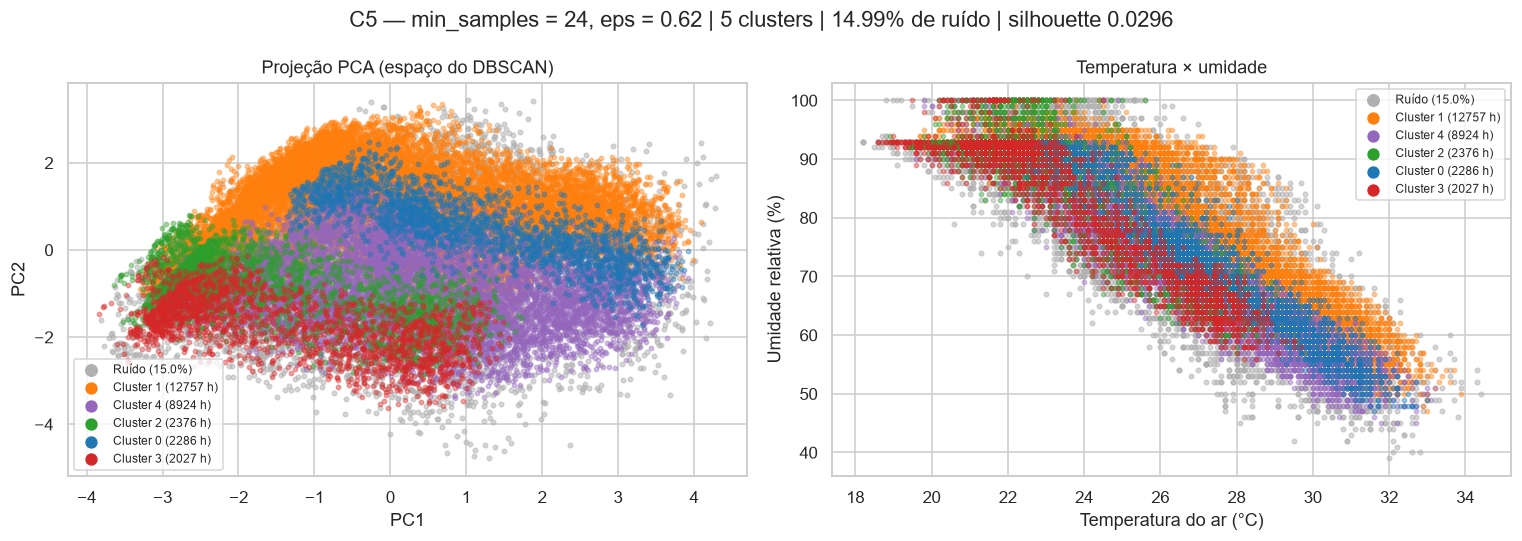

In [18]:
plotar_clusters("C5")

**C6 · `min_samples = 24`, `eps = 0,66`** — 4 clusters, 10,06% de ruído, silhouette 0,0212. **Escolhida:** duas massas (13,3 e 11,8 mil horas) e dois grupos de ~2,5 e ~2,4 mil, com a maior silhouette entre as aprovadas.

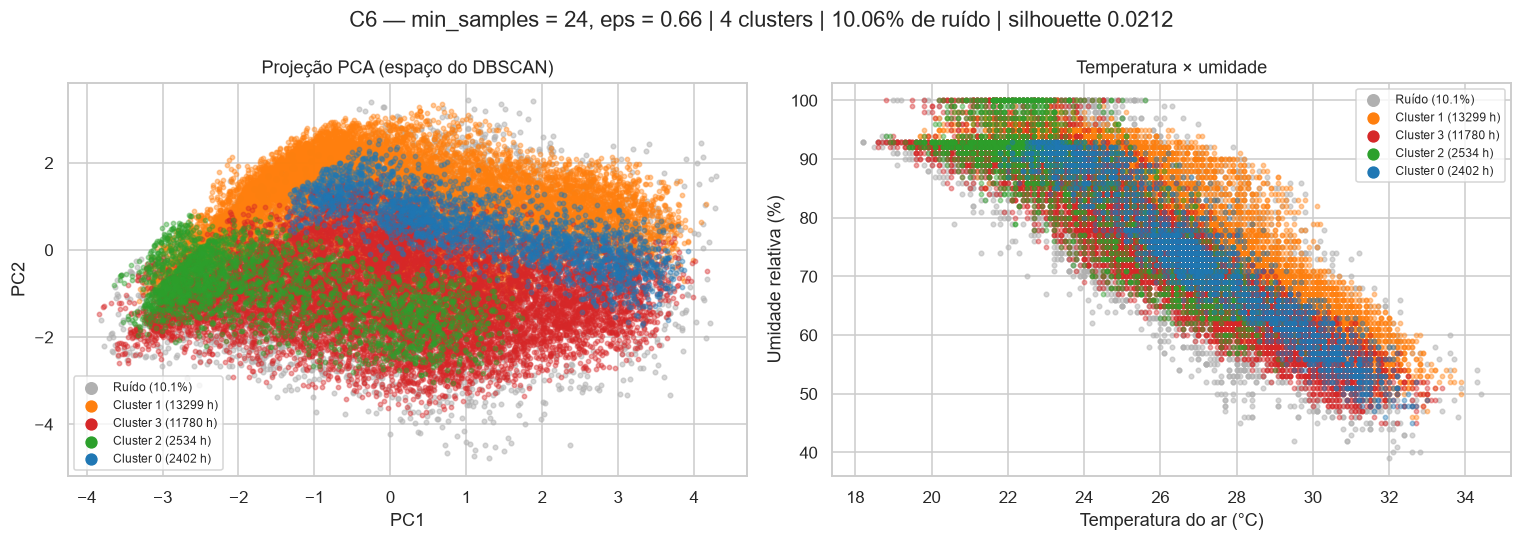

In [19]:
plotar_clusters("C6")